# Session 06, Part 1 — Coordination patterns

One request that needs two independent domains, solved four ways. The specialists are always
**Deep Agents** (`create_deep_agent`); what changes is **who decides** and **where the results go**:

| Part | Pattern | Who decides | Built with |
|---|---|---|---|
| 1 | Subagents (supervisor) | the main agent calls specialists as tools (`task`) | Deep Agents |
| 2 | Skills | one agent loads domain instructions on demand | Deep Agents |
| 3 | Router | a classification step, then specialists in parallel | LangGraph `Send` + Deep Agents |
| 4 | Handoffs | the active agent transfers the conversation | LangGraph `Command` + Deep Agents |

Part 5 puts the model calls and tokens of Parts 1–3 side by side.

Docs: [Multi-agent overview](https://docs.langchain.com/oss/python/langchain/multi-agent) ·
[Deep Agents subagents](https://docs.langchain.com/oss/python/deepagents/subagents) ·
[Router](https://docs.langchain.com/oss/python/langchain/multi-agent/router) ·
[Handoffs](https://docs.langchain.com/oss/python/langchain/multi-agent/handoffs)

In [1]:
import logging
import os

from dotenv import load_dotenv
from langchain.chat_models import init_chat_model

logging.basicConfig(level=logging.INFO, format="%(levelname)s | %(message)s")
for noisy in ("httpx", "httpx2"):  # HTTP clients log every request at INFO
    logging.getLogger(noisy).setLevel(logging.WARNING)
logger = logging.getLogger(__name__)

# ── Keys and models (.env of this session folder) ─────────────────────────────
load_dotenv()
for name in ("OPENAI_API_KEY", "TAVILY_API_KEY"):
    if not os.getenv(name, "").strip():
        raise RuntimeError(f"Missing {name}: copy .env.example to .env in the session folder and fill it in")
model = init_chat_model(os.getenv("MODEL", "openai:gpt-6-luna"))  # every agent of this notebook
logger.info("Model: %s", model.model_name)

from utils import SESSION_DIR, internet_search, prompt, stream  # notebooks/utils.py

INFO | Model: gpt-6-luna


## The request and the two specialists

The question has two parts that do not depend on each other, which is the case where several agents help.
Each specialist is a dict in the Deep Agents subagent format (`name`, `description`, `system_prompt`, `tools`,
`model`, `middleware`). `ToolCallLimitMiddleware` caps each one at 2 searches: a budget per agent, so a run cannot
spend more than planned.

In [2]:
from langchain.agents.middleware import ToolCallLimitMiddleware

QUESTION = ("We plan to electrify our home. How well do air-source heat pumps work in freezing weather, "
            "and how long do electric-car batteries usually last?")

DOMAINS = {
    "heat-pump-researcher": "air-source heat pumps: efficiency (COP), cold-weather performance",
    "ev-battery-researcher": "electric-vehicle batteries: lifespan, capacity loss per year, warranties",
}


def specialist(name: str) -> dict:
    """A specialist in the Deep Agents subagent format; the same spec is reused by every pattern below."""
    return {
        "name": name,
        "description": f"Researches {DOMAINS[name]} on the web and returns cited bullets.",
        "system_prompt": prompt("researcher") + f"\n\n# Domain\nAnswer only the part of the question about {DOMAINS[name]}.",
        "tools": [internet_search],
        "model": model,
        "middleware": [ToolCallLimitMiddleware(tool_name="internet_search", run_limit=2, exit_behavior="continue")],
    }


SPECIALISTS = [specialist(name) for name in DOMAINS]
COST = {}  # pattern -> usage totals, compared in Part 5
print("specialists:", [s["name"] for s in SPECIALISTS])

specialists: ['heat-pump-researcher', 'ev-battery-researcher']


## Part 1 — Subagents: the main agent calls specialists as tools

<img src="images/lc_pattern_subagents.png" width="520">

`create_deep_agent(subagents=[...])` gives the main agent a `task(description, subagent_type)` tool. The main
agent decides which specialist to call and with which task; each specialist runs its own loop in its own context
and returns only its final answer. Two `task` calls in the same model message run in parallel.

In [3]:
from deepagents import create_deep_agent

supervisor = create_deep_agent(
    name="supervisor",
    model=model,
    subagents=SPECIALISTS,
    system_prompt=prompt("supervisor"),
)

result, usage, seconds = await stream(supervisor, QUESTION, main="supervisor")
usage.table(f"Subagents: {seconds:.0f} s")
COST["Subagents"] = {**usage.total(), "seconds": seconds}

[supervisor] → task({"description": "Research how well modern air-source heat pumps work in freezing and cold …)
[supervisor] → task({"description": "Research typical electric vehicle battery lifespan and degradation/capaci…)
[heat-pump-researcher] → internet_search({"query": "NREL cold climate air source heat pump performance COP low temperature field st…)
[ev-battery-researcher] → internet_search({"query": "site:energy.gov electric vehicle battery lifespan degradation capacity loss war…)


INFO | internet_search('NREL cold climate air source heat pump performance COP low temperatur…) -> ok 2792 ms


[heat-pump-researcher] ← internet_search: [{"title": "Field Validation of Air-Source Heat Pumps for Cold Climates - National Laborat…


INFO | internet_search('site:energy.gov electric vehicle battery lifespan degradation capacit…) -> ok 4441 ms


[ev-battery-researcher] ← internet_search: [{"title": "FOTW #1339, April 22, 2024: Plug-in Electric Vehicle Battery Replacements Due …
[heat-pump-researcher] → internet_search({"query": "DOE Energy Saver cold climate heat pump works below freezing COP efficiency low…)
[ev-battery-researcher] → internet_search({"query": "Geotab EV battery degradation average 1.8% per year warranty 8 years 100000 mil…)


INFO | internet_search('Geotab EV battery degradation average 1.8% per year warranty 8 years …) -> ok 1747 ms


[ev-battery-researcher] ← internet_search: [{"title": "2024 Battery Degradation Update | Geotab", "url": "https://www.geotab.com/uk/p…


INFO | internet_search('DOE Energy Saver cold climate heat pump works below freezing COP effi…) -> ok 3639 ms


[heat-pump-researcher] ← internet_search: [{"title": "How Heat Pumps Perform in Below-Freezing Temperatures", "url": "https://www.wa…
[supervisor] ← task: - EV batteries typically lose about **1.8% of capacity per year** in Geotab’s 2024 analysi…
[supervisor] ← task: - Modern variable-speed air-source heat pumps can provide useful heat in freezing and sub-…
- **Air-source heat pumps:** Modern cold-climate models can provide useful heat in freezing and sub-zero weather, but efficiency and heating capacity generally drop as it gets colder. Performance depends on the model and conditions, so check its low-temperature capacity and whether it needs backup heat for your climate. [NREL field study](https://research-hub.nlr.gov/en/publications/field-validation-of-air-source-heat-pumps-for-cold-climates) · [Xcel Energy summary of cold-weather testing](https://newsroom.xcelenergy.com/news/nrel-and-xcel-energy-study-looks-at-advancing-technology-needed-for-the-clean-energy-transition-MC2TQFCSZVIV

The `[heat-pump-researcher]` and `[ev-battery-researcher]` lines are steps inside the subagents: their searches
stay in their own context. The supervisor only receives each subagent's last message as the result of `task`.

## Part 2 — Skills: one agent loads domain instructions on demand

<img src="images/lc_pattern_skills.png" width="460">

Same domain knowledge, written as two Skills (`skills/heat-pumps/SKILL.md`, `skills/ev-batteries/SKILL.md`).
There is no second agent: the agent sees only the skill names and descriptions, reads a `SKILL.md` when the
question needs it, and does the searches itself, so every search result lands in its own context.

In [4]:
from deepagents.backends import CompositeBackend, FilesystemBackend, StateBackend

skills_agent = create_deep_agent(
    name="skills-agent",
    model=model,
    tools=[internet_search],
    skills=["/skills/"],
    backend=CompositeBackend(default=StateBackend(), routes={
        "/skills/": FilesystemBackend(root_dir=(SESSION_DIR / "skills").resolve(), virtual_mode=True)}),
    system_prompt=prompt("researcher"),
    middleware=[ToolCallLimitMiddleware(tool_name="internet_search", run_limit=4, exit_behavior="continue")],
)

result, usage, seconds = await stream(skills_agent, QUESTION, main="skills-agent")
usage.table(f"Skills: {seconds:.0f} s")
COST["Skills"] = {**usage.total(), "seconds": seconds}

[skills-agent] → read_file({"file_path": "/skills/heat-pumps/SKILL.md", "offset": 0, "limit": 1000})
[skills-agent] → read_file({"file_path": "/skills/ev-batteries/SKILL.md", "offset": 0, "limit": 1000})
[skills-agent] ← read_file: @@ lines 1-10 of 10 @@ --- name: heat-pumps description: Research air-source heat pumps (e…
[skills-agent] ← read_file: @@ lines 1-10 of 10 @@ --- name: ev-batteries description: Research electric-vehicle batte…
[skills-agent] → internet_search({"query": "air source heat pump COP freezing 32°F 5°F government cold climate field study"…)
[skills-agent] → internet_search({"query": "electric vehicle battery degradation average per year fleet study warranty 8 ye…)


INFO | internet_search('electric vehicle battery degradation average per year fleet study war…) -> ok 1668 ms


[skills-agent] ← internet_search: [{"title": "How Long Do Electric Car Batteries Last? (2026 Lifespan Guide)", "url": "https…


INFO | internet_search('air source heat pump COP freezing 32°F 5°F government cold climate fi…) -> ok 2290 ms


[skills-agent] ← internet_search: [{"title": "Cold Climate Field Study of the Effect of Defrost Controls on the Integrated P…
- **Air-source heat pumps can heat homes in freezing weather**, especially cold-climate models, but their heating capacity and efficiency generally fall as the outdoor temperature drops. A Minnesota field project says newer models can operate down to about **0°F to −13°F**; operation at those temperatures doesn’t necessarily mean full heating capacity. [https://www.mncee.org/cold-climate-air-source-heat-pump-field-assessment-closed](https://www.mncee.org/cold-climate-air-source-heat-pump-field-assessment-closed)
- One cold-climate specification uses a **COP of at least 1.75 at 5°F** as a benchmark—meaning 1.75 units of heat delivered per unit of electricity used. That’s a specification threshold, not a promise that every heat pump will achieve it. [https://www.aceee.org/wp-content/uploads/proceedings-1980-2020/2016/1_700.pdf](https://www.aceee.org/wp-content/upl

## Part 3 — Router: classify, run the specialists in parallel, synthesize

<img src="images/lc_pattern_router.png" width="560">

A router is a fixed workflow, so it is written in **LangGraph** (a *custom workflow*): `classify` asks the model
which domains the question needs (structured output), `Send` starts one `research` node per domain in the same
step (parallel), each node runs a specialist Deep Agent built from the same spec, and `synthesize` writes the
answer. The router itself keeps no conversation.

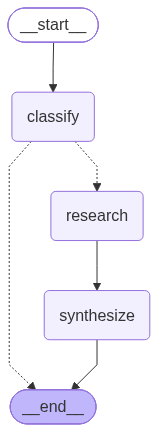

In [5]:
import operator
from typing import Annotated, Literal

from langgraph.graph import END, START, StateGraph
from langgraph.types import Send
from pydantic import BaseModel, Field
from typing_extensions import TypedDict


class RouterState(TypedDict):
    question: str
    domains: list[str]
    findings: Annotated[list[str], operator.add]  # each parallel branch appends its result
    answer: str


class Route(BaseModel):
    domains: list[Literal["heat-pump-researcher", "ev-battery-researcher"]] = Field(
        description="Every specialist the question needs; empty if none")


def agent_from_spec(spec: dict):
    """A standalone Deep Agent built from a subagent spec (same prompt, tools, model, budget)."""
    return create_deep_agent(name=spec["name"], model=spec["model"], tools=spec["tools"],
                             system_prompt=spec["system_prompt"], middleware=spec["middleware"])


AGENTS = {spec["name"]: agent_from_spec(spec) for spec in SPECIALISTS}


async def classify(state: RouterState) -> dict:
    route = await model.with_structured_output(Route).ainvoke(
        [{"role": "system", "content": "Pick the specialists this question needs. Specialists: "
          + "; ".join(f"{k}: {v}" for k, v in DOMAINS.items())},
         {"role": "user", "content": state["question"]}])
    logger.info("router -> %s", route.domains)
    return {"domains": route.domains}


def fan_out(state: RouterState):
    return [Send("research", {"question": state["question"], "domain": d}) for d in state["domains"]] or END


async def research(payload: dict) -> dict:
    answer = await AGENTS[payload["domain"]].ainvoke({"messages": [{"role": "user", "content": payload["question"]}]})
    return {"findings": [f"## {payload['domain']}\n{answer['messages'][-1].text}"]}


async def synthesize(state: RouterState) -> dict:
    reply = await model.ainvoke([
        {"role": "system", "content": "Combine the specialists' findings into one short answer. Keep every url."},
        {"role": "user", "content": state["question"] + "\n\n" + "\n\n".join(state["findings"])}])
    return {"answer": reply.text}


builder = StateGraph(RouterState)
builder.add_node("classify", classify)
builder.add_node("research", research)
builder.add_node("synthesize", synthesize)
builder.add_edge(START, "classify")
builder.add_conditional_edges("classify", fan_out, ["research", END])
builder.add_edge("research", "synthesize")
builder.add_edge("synthesize", END)
router = builder.compile()

from IPython.display import Image

Image(router.get_graph().draw_mermaid_png(), width=260)

In [6]:
import time

from utils import Usage

usage, started = Usage(), time.monotonic()
out = await router.ainvoke({"question": QUESTION}, {"callbacks": [usage]})
seconds = time.monotonic() - started
print(out["answer"])
usage.table(f"Router: {seconds:.0f} s")
COST["Router"] = {**usage.total(), "seconds": seconds}

INFO | router -> ['heat-pump-researcher', 'ev-battery-researcher']
INFO | internet_search('air source heat pump cold weather performance COP freezing temperatur…) -> ok 2142 ms
INFO | internet_search('DOE air source heat pumps cold climates freezing weather work down to…) -> ok 1960 ms
INFO | internet_search('EV battery typical lifespan capacity degradation per year warranty 8 …) -> ok 7843 ms
INFO | internet_search('Geotab EV battery degradation 2024 average 1.8% annual 8 year warrant…) -> ok 2396 ms


Air-source heat pumps can heat homes in freezing weather, though their efficiency falls as temperatures drop. Many modern cold-climate models have a COP of at least 1.75 at 5°F; check a model’s low-temperature capacity, since an undersized system or extreme cold may call for supplemental heat. [Heat-pump performance](https://homes.rewiringamerica.org/articles/heating-and-cooling/heat-pumps-cold-weather) · [Choosing a cold-climate model](https://www.carrier.com/us/en/residential/hvac-resources/heat-pumps/cold-climate-heat-pump)

EV batteries typically lose about 1.8–2.3% of their capacity per year, though use and charging habits affect the rate. One estimate puts useful battery life at 15–20 years. Many warranties cover about 8 years or 100,000 miles and guarantee at least 70% capacity, but terms vary by vehicle and location. [Battery health](https://www.geotab.com/blog/ev-battery-health) · [Battery life and warranties](https://www.evconnect.com/blog/how-long-does-an-electric-car-batter

## Part 4 — Handoffs: the active agent changes and talks to the user directly

<img src="images/lc_pattern_handoffs.png" width="520">

This follows the docs' *multiple agent subgraphs* version: each specialist is a node of a LangGraph graph and has
a `transfer_to_…` tool. The tool returns `Command(goto=…, graph=Command.PARENT)` and records `active_agent` in the
graph state. With a checkpointer, the **next user turn** starts at the active agent directly, without routing
again. Handoffs suit conversations (support, intake), not parallel research: one agent works at a time.

In [7]:
from langchain.agents import AgentState
from langchain.messages import AIMessage, ToolMessage
from langchain.tools import ToolRuntime, tool
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.types import Command
from typing_extensions import NotRequired


class HandoffState(AgentState):
    active_agent: NotRequired[str]


def transfer_tool(target: str):
    @tool(f"transfer_to_{target.replace('-', '_')}", description=f"Transfer the conversation to the {target}.")
    def transfer(runtime: ToolRuntime) -> Command:
        last_ai = next(m for m in reversed(runtime.state["messages"]) if isinstance(m, AIMessage))
        done = ToolMessage(f"Transferred to {target}", tool_call_id=runtime.tool_call_id)
        return Command(goto=target, update={"active_agent": target, "messages": [last_ai, done]},
                       graph=Command.PARENT)
    return transfer


def handoff_agent(name: str, other: str):
    """A specialist that talks to the user directly; questions outside its domain go to the other specialist."""
    spec = specialist(name)
    return create_deep_agent(
        name=name, model=spec["model"], tools=[internet_search, transfer_tool(other)],
        middleware=spec["middleware"],
        system_prompt=prompt("researcher") + f"\n\n# Domain\nYou cover {DOMAINS[name]}. If the question is about "
        f"another domain, call transfer_to_{other.replace('-', '_')} right away instead of answering.")


HANDOFF_AGENTS = {"heat-pump-researcher": handoff_agent("heat-pump-researcher", "ev-battery-researcher"),
                  "ev-battery-researcher": handoff_agent("ev-battery-researcher", "heat-pump-researcher")}


def node(name: str):
    async def call(state: HandoffState):
        return await HANDOFF_AGENTS[name].ainvoke(state)
    return call


def route_initial(state: HandoffState) -> str:
    return state.get("active_agent") or "heat-pump-researcher"


def route_after(state: HandoffState) -> str:
    last = state["messages"][-1]
    return END if isinstance(last, AIMessage) and not last.tool_calls else route_initial(state)


hb = StateGraph(HandoffState)
for name in HANDOFF_AGENTS:
    hb.add_node(name, node(name))
    hb.add_conditional_edges(name, route_after, [*HANDOFF_AGENTS, END])
hb.add_conditional_edges(START, route_initial, list(HANDOFF_AGENTS))
handoffs = hb.compile(checkpointer=InMemorySaver())

In [8]:
HANDOFF_TURNS = [
    "How long do electric-car batteries usually last?",  # starts at the heat-pump agent -> transfer
    "And what do the warranties usually cover?",          # follow-up: goes straight to the active agent
]
config = {"configurable": {"thread_id": "handoff-01"}}
for turn in HANDOFF_TURNS:
    print(f"\nUSER: {turn}")
    state, usage, seconds = await stream(handoffs, turn, config, show_tokens=False)
    print("ANSWER:", state["messages"][-1].text[:600])
    print(f"active_agent = {state.get('active_agent')} | model calls this turn: {usage.total()['calls']}")


USER: How long do electric-car batteries usually last?
[heat-pump-researcher] → transfer_to_ev_battery_researcher({})
[main] ← transfer_to_ev_battery_researcher: Transferred to ev-battery-researcher
[ev-battery-researcher] → internet_search({"query": "electric vehicle battery typical lifespan years 15 years degradation study warr…)


INFO | internet_search('electric vehicle battery typical lifespan years 15 years degradation …) -> ok 2504 ms


[ev-battery-researcher] ← internet_search: [{"title": "Electric Vehicle Batteries: Warranties and Lifetimes", "url": "https://louisia…
[ev-battery-researcher] → internet_search({"query": "site:energy.gov electric vehicle battery expected lifespan 15 years battery war…)


INFO | internet_search('site:energy.gov electric vehicle battery expected lifespan 15 years b…) -> ok 1812 ms


[ev-battery-researcher] ← internet_search: [{"title": "Electricity - Wikipedia", "url": "https://en.wikipedia.org/wiki/Electricity", …

ANSWER: - Electric-car batteries commonly last about **12–15 years**; many may remain usable longer, though their range gradually declines. [https://louisianacleanfuels.starchapter.com/blog/id/541](https://louisianacleanfuels.starchapter.com/blog/id/541)
- Real-world data analysis from Geotab estimates an average lifespan of **around 13 years or more**; actual longevity varies with the vehicle, climate, charging habits, and use. [https://www.geotab.com/blog/ev-battery-health](https://www.geotab.com/blog/ev-battery-health)
active_agent = ev-battery-researcher | model calls this turn: 4

USER: And what do the warranties usually cover?
[ev-battery-researcher] → internet_search({"query": "electric vehicle battery warranty typically 8 years 100,000 miles capacity 70% …)


INFO | internet_search('electric vehicle battery warranty typically 8 years 100,000 miles cap…) -> ok 2803 ms


[ev-battery-researcher] ← internet_search: [{"title": "Car Warranty Coverage on an Electric Car Battery | U.S. News", "url": "https:/…
[ev-battery-researcher] → internet_search({"query": "EV battery warranty covers defects repair replacement degradation capacity thre…)


INFO | internet_search('EV battery warranty covers defects repair replacement degradation cap…) -> ok 2619 ms


[ev-battery-researcher] ← internet_search: [{"title": "Electric Bus Battery Warranty Guide: What's Covered in 2026", "url": "https://…

ANSWER: - In the U.S., the traction-battery warranty is typically **8 years or 100,000 miles, whichever comes first**; some manufacturers offer longer coverage. [Midtronics](https://www.midtronics.com/blog/what-warranty-does-an-ev-battery-cover)
- It generally covers **battery defects or failure**, and often excessive capacity loss—commonly if capacity drops below about **70% of its original level** during the warranty period. [Midtronics](https://www.midtronics.com/blog/what-warranty-does-an-ev-battery-cover)
- If a covered problem occurs, the manufacturer typically repairs or replaces the battery un
active_agent = ev-battery-researcher | model calls this turn: 3


On the first turn the heat-pump agent called `transfer_to_ev_battery_researcher`; on the second turn the graph
started at `ev-battery-researcher` because `active_agent` was saved in the thread. To chat with the handoff graph
yourself, uncomment the cell below.

In [9]:
# config = {"configurable": {"thread_id": "handoff-live"}}
# while (turn := input("You (empty to stop): ").strip()):
#     state, usage, seconds = await stream(handoffs, turn, config, show_tokens=False)
#     print(state["messages"][-1].text, f"\n(active_agent = {state.get('active_agent')})")

## Part 5 — Same request, three patterns, three costs

The numbers come from the runs above (they change from run to run). Compare them with the docs' table
("Multi-domain" scenario): Subagents and Router run the domains in parallel and keep each domain's search results
out of the main context; Skills needs fewer calls but loads everything into one context.

In [10]:
print(f"{'pattern':<12}{'model calls':>12}{'input tok':>11}{'output tok':>11}{'seconds':>9}")
for pattern, c in COST.items():
    print(f"{pattern:<12}{c['calls']:>12}{c['input']:>11,}{c['output']:>11,}{c['seconds']:>9.0f}")

pattern      model calls  input tok output tok  seconds
Subagents              8     19,311      1,734       26
Skills                 3      9,810      1,118       13
Router                 8     16,857      1,042       22
